# Generation of synthetic C. elegans connectomes

As a first validation, we generate synthetic connectomes taking the last connectome (A.2) as our blueprint and the corresponding developmental parameters of each snapshot, following the likelihood given by our Poisson model. 

In here, we exemplify this with the reduced version of the connectomes, as these are the data that we provide in the repository.

In [1]:
#Our package:
from aligner.networksHandling import helper as helper_networks
from aligner.poissonAlignment import helper as helper_poisson
from aligner.montecarlo import helper as helper_montecarlo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

In [3]:
original_A = helper_networks.load_networks(data_folder="../../data/processed/celegans/", 
                                           net_ids=[t for t in range(1,9)],
                                           file_prefix="reduced_")

In [4]:
blueprint = original_A[-1] #we take A2 as the blueprint to generate connectomes from

ST = helper_poisson.get_ST(original_A) #strength of the densest conncetome
alphas = helper_poisson.get_alpha(original_A, ST) #alphas of the connectomes we will generate
print(f"Set of developmental parameters: {alphas}")

Set of developmental parameters: [0.2266881  0.26848875 0.36495177 0.54421222 0.54662379 0.88665595
 1.         1.        ]


In [5]:
synthetic_A = helper_poisson.synthesize_networks(blueprint, alphas, seed=99) 

T, N, N = synthetic_A.shape
print(f"T (number of snapshots) = {T}\nN (number of nodes) = {N}")

T (number of snapshots) = 8
N (number of nodes) = 60


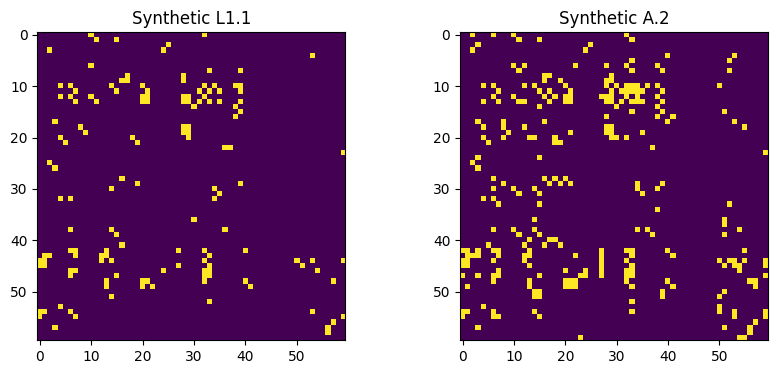

In [6]:
#only showing presence/absence of synapses (for visualization purposes, we actually consider synaptic counts)
plt.figure(figsize=(10, 4))
for i, (A, title) in enumerate(zip([synthetic_A[0], synthetic_A[-1]], ["L1.1", "A.2"])):
    plt.subplot(1, 2, i+1)
    plt.imshow(A>0, cmap='viridis')
    plt.title(f"Synthetic {title}")
plt.show()

In [9]:
!mkdir -p ../../data/processed/synthetic_celegans/

In [10]:
for n_dataset, mat in enumerate(synthetic_A):
    pd.DataFrame(data=mat).to_csv(f"../../data/processed/synthetic_celegans/reduced_adjMat_{str(n_dataset)}.csv")